# Цены на квартиры в Петербурге и области

## Содержание

- [Описание](#section-1)
- [Импорт библиотек Python](#section-2)
- [Загрузка данных](#section-3)
- [Предобработка данных](#section-4)
- [Расчёты и добавление результатов в таблицу](#section-5)
- [Исследовательский анализ данных](#section-6)
- [Общий вывод](#section-7)

<a id="section-1"></a>

## Описание

На исследовании находятся данные, предоставленные агентством `Яндекс.Недвижимость` - **архив о продажах квартир в Санкт-Петербурге и ближайших районах за последние несколько лет**.

---

**Задача**

Провести исследование данных и установить взаимосвязь между признаками набора данных и целевой переменной - стоимость квартир - в целях последующего построения модели прогнозирования стоимости жилья.

Таким образом, задача: **Определить, что влияет на конечную стоимость квартиры**.

---

**Описание данных**

* **children** - количество детей в семье;
* **days_employed** - общий трудовой стаж в днях;
* **dob_years** - возраст клиента в годах;
* **education** - уровень образования клиента;
* **education_id** - идентификатор уровня образования;
* **family_status** - семейное положение;
* **family_status_id** - идентификатор семейного положения;
* **gender** - пол клиента;
* **income_type** - тип занятости;
* **debt** - имел ли задолженность по возврату кредитов;
* **total_income** - ежемесячный доход;
* **purpose** - цель получения кредита.

<a id="section-2"></a>

## Импорт библиотек Python

Данный этап характеризуется следующими последовательными действиями:

1. Импорт библиотек Python для работы над проектом в части:
  * работа с табличными данными:
    * numpy;
    * pandas.
  * визуализация данных:
    * matplotlib;
    * seaborn.
2. Инициализация констант для работы с проектом;
3. Формирование вывода по итогам данного этапа.

In [1]:
# импорт библиотек Python

## работа с табличными данными
## визуализация данных
import os
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# инициализация переменных проекта

DIR_PATH = os.getcwd()
DATA_DIR = os.environ.get('PORTFOLIO_DATA_DIR', '../data/raw')
DATA_NAME = 'real_estate_data.csv'

# сборка пути к данным
DATA_PATH = os.path.join(DIR_PATH, DATA_DIR, DATA_NAME)

In [3]:
# установки настроек визуализации для всего проекта
plt.rcParams['figure.figsize'] = (12, 5)

**Вывод**

1. Импортированы библиотеки Python для работы над проектом в части:
  * работы с табличными данными:
    * numpy;
    * pandas.
  * визуализации данных:
    * matplotlib;
    * seaborn.
2. Инициализированы константы для работы с проектом:
  * **DIR_PATH** - текущая рабочая директория;
  * **DATA_DIR** - директория с хранимыми данными;
  * **DATA_NAME** - название исходного набора данных.

<a id="section-3"></a>

## Загрузка данных

Данный этап характеризуется следующими последовательными действиями:

1. Загрузка набора данных в рабочую среду Jupyter Notebook - инициализирована переменной `data`;
2. инициализирована пользовательских функций предварительного обзора набора данных;
3. Вывод на экран основной информации о наборе данных для формирования плана последующих действий;
4. Формирование вывода по итогам данного этапа.

In [4]:
# загрузка данных в рабочую среду
data = pd.read_csv(DATA_PATH, sep ='\t')

In [5]:
# инициализирована пользовательской функции просмотра пропущенных значений
def na_statistics(df : pd.DataFrame) -> None:
    df_na = df.isna().sum().to_frame()
    df_na.columns = ['na_count']
    df_na['na_share'] = round(df_na['na_count'] / df.shape[0] * 100.0, 2)
    print('Пропущенные значения в наборе данных')
    display(df_na)

In [6]:
# инициализирована пользовательской функции просмотра названий признаков и типов данных
def feature_info(df : pd.DataFrame) -> None:
    df_features = df.dtypes.to_frame()
    df_features.columns = ['feature_type']
    print('Названия признаков набора данных и их типы')
    display(df_features)

In [7]:
# инициализирована пользовательской функции построения распределений количественных непрерывных показателей
def num_distribution(column : str, bins : int):
    plt.subplot(1, 2, 1)
    plt.xlabel(f'Значения признака \n{column}')
    plt.ylabel('Частота значений признака')
    plt.title(f'Гистограмма значений \n{column}', fontsize = 10)
    sns.histplot(data = data, x = data[column], bins = bins)
    plt.subplot(1, 2, 2)
    plt.xlabel(f'Значения признака \n{column}')
    plt.title(f'Диаграмма размаха значений \n{column}', fontsize = 10)
    sns.boxplot(data = data, x = data[column])
    plt.grid(False)
    plt.show()

In [8]:
# инициализация пользовательской функции построения распределений количественных дискретных показателей
def discr_distribution(column : str):
    ax = (
        sns.countplot(
            data = data,
            x = column,
            stat='count'
        )
    )

    ax.set(
        xlabel = f'Значения признака {column}',
        ylabel = 'Количество значений по признаку',
        title = f'Распределение значнений по признаку {column}'
    )
    plt.xticks(rotation = 45)
    plt.show()

In [9]:
# вывод на экран общей статистики по пропущенным значениям
na_statistics(data)

Пропущенные значения в наборе данных


,na_count,na_share
total_images,0,0.00
last_price,0,0.00
total_area,0,0.00
first_day_exposition,0,0.00
rooms,0,0.00
ceiling_height,9195,38.80
floors_total,86,0.36
living_area,1903,8.03
floor,0,0.00
is_apartment,20924,88.29


**Вывод по промежуточному этапу**:

Обнаружено большое количество пропущенных значений по описательным признакам набора данных.

На этапе предобработки данных будет определены пути устранения пропущенных значений для каждого из признаков датасета (ручная замена значений, исключение строк из набора и др.).

In [10]:
# вывод на экран информации по признакам и их типам
feature_info(data)

Названия признаков набора данных и их типы


,feature_type
total_images,int64
last_price,float64
total_area,float64
first_day_exposition,object
rooms,int64
ceiling_height,float64
floors_total,float64
living_area,float64
floor,int64
is_apartment,object


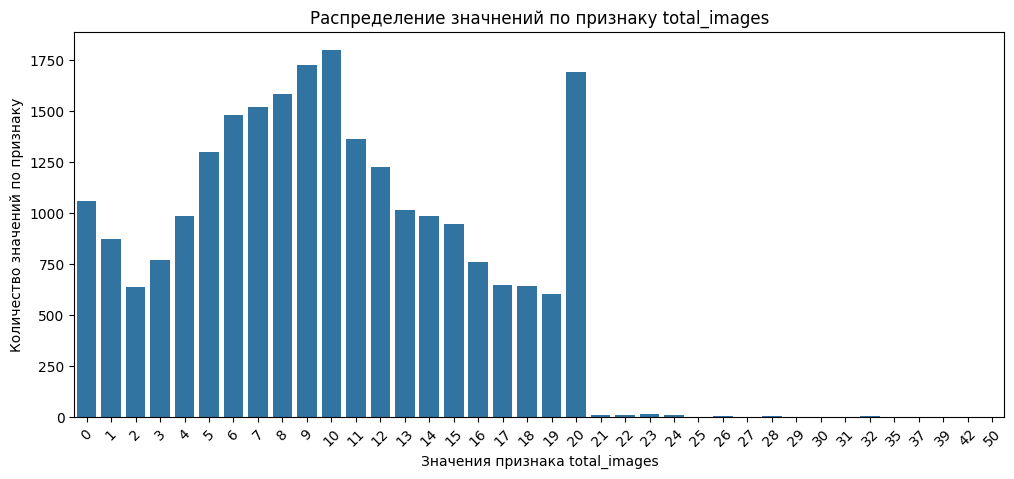

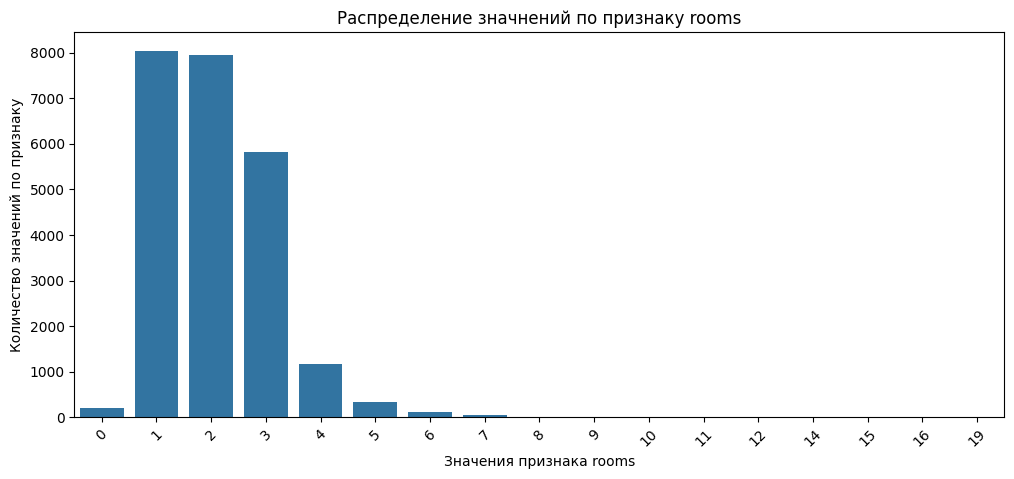

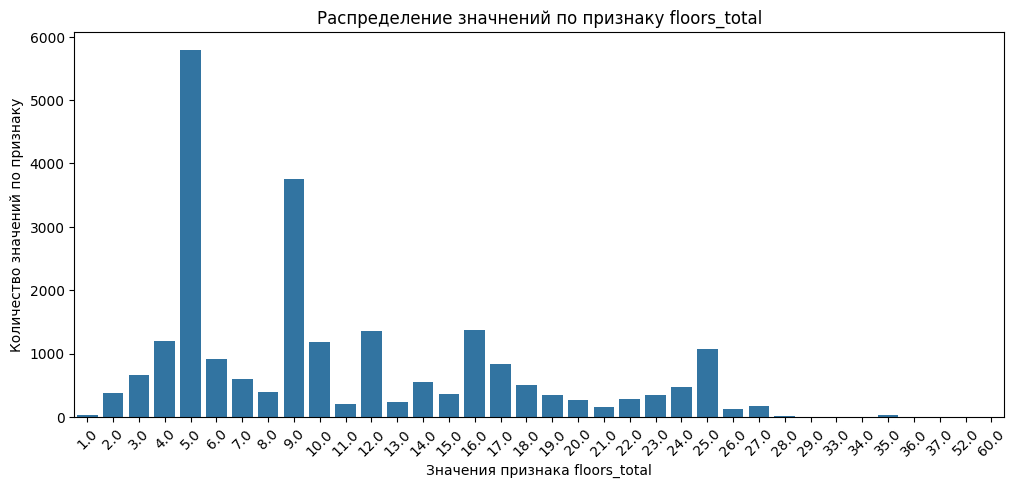

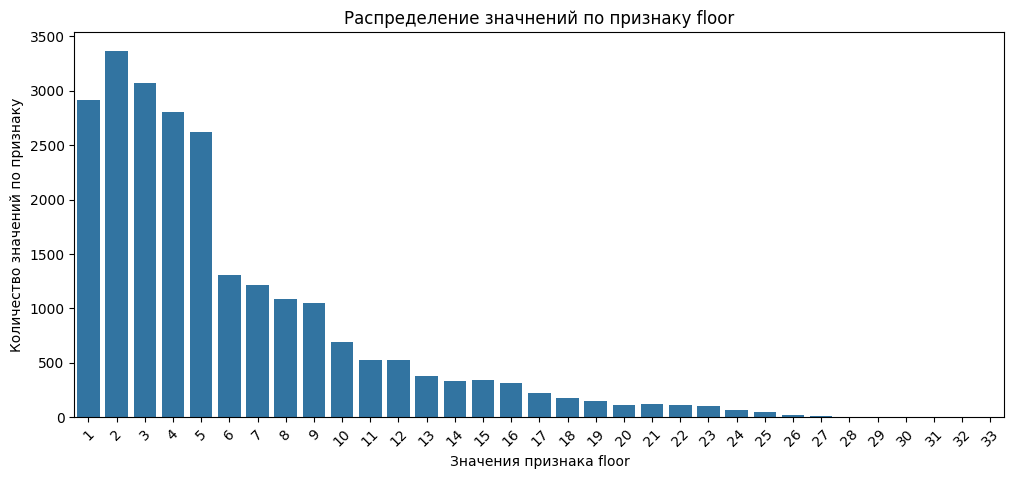

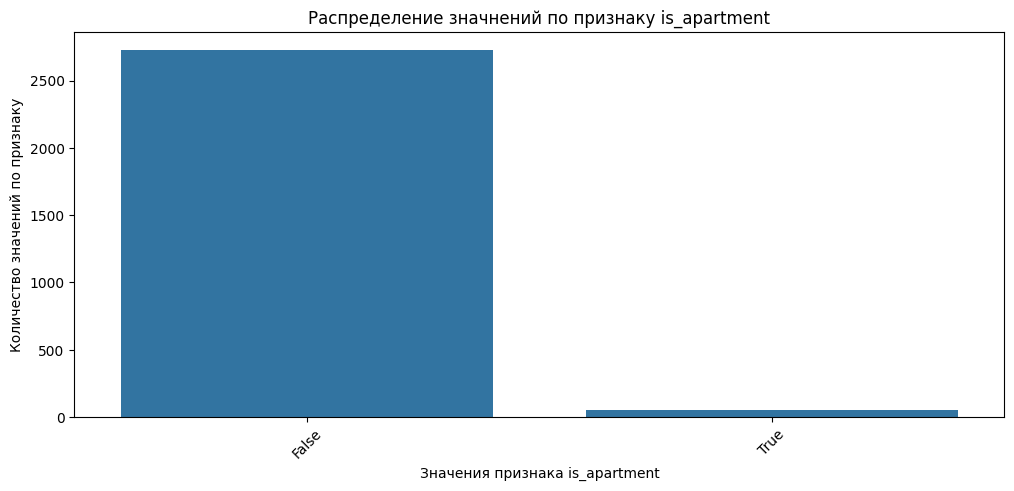

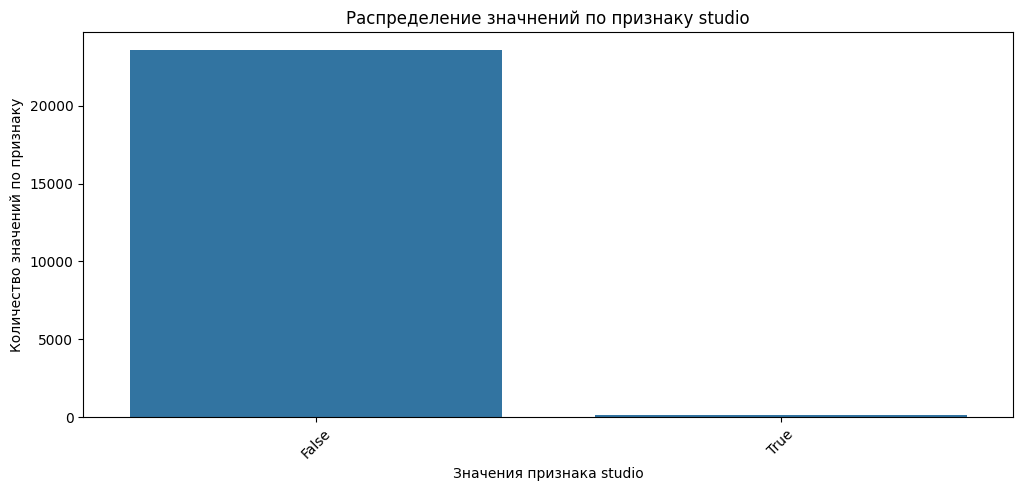

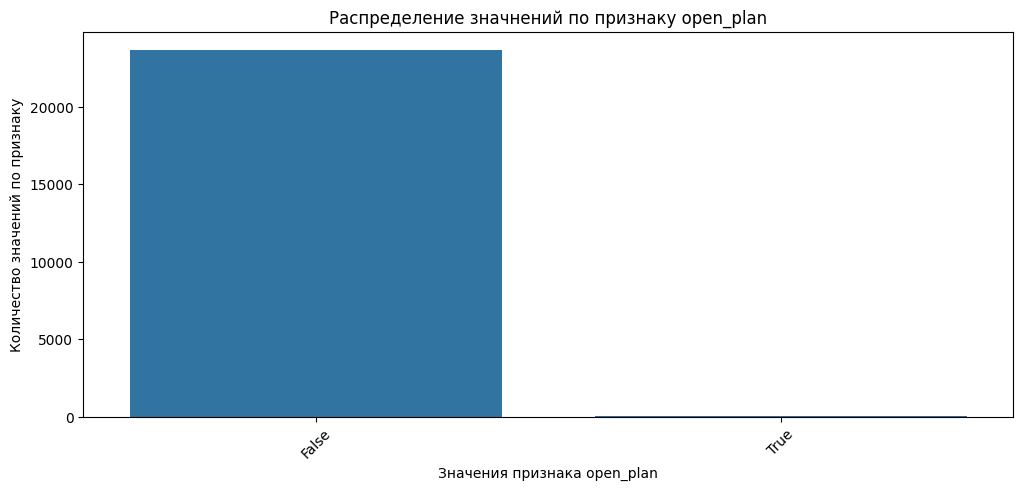

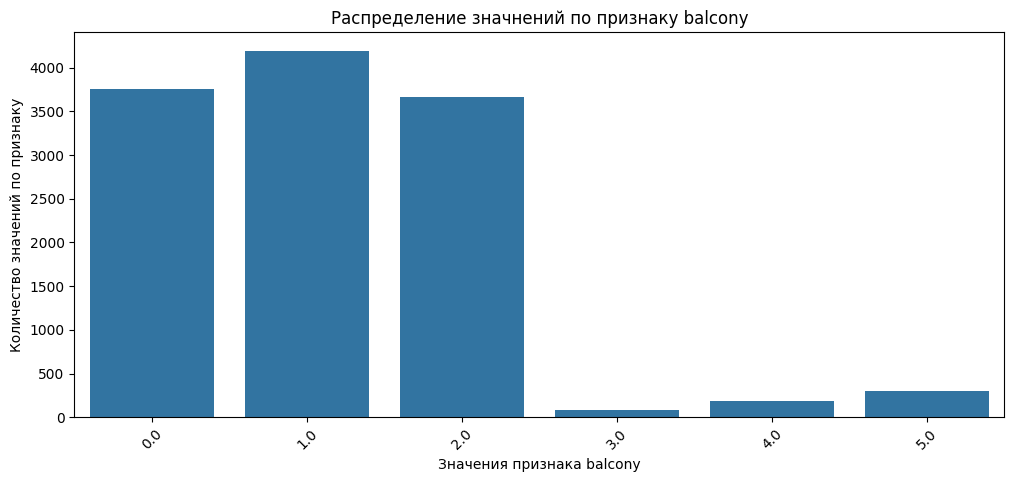

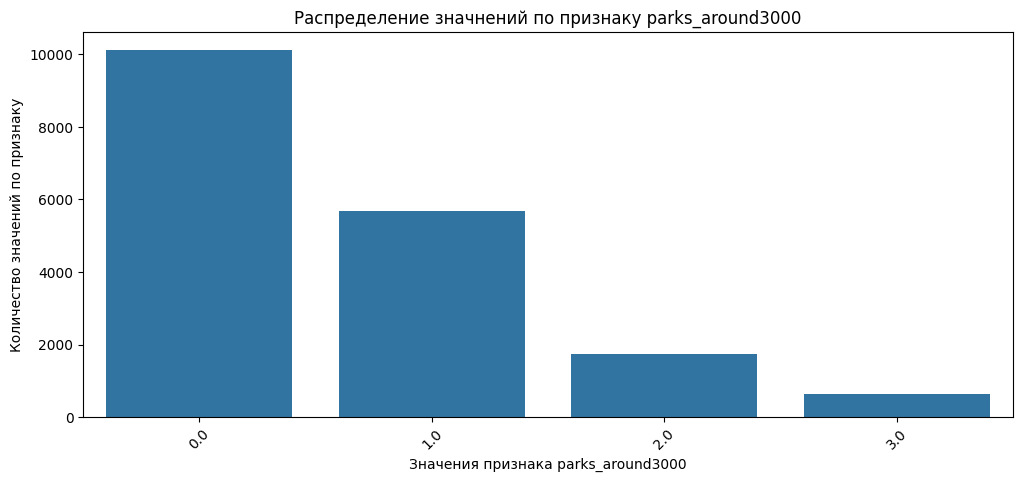

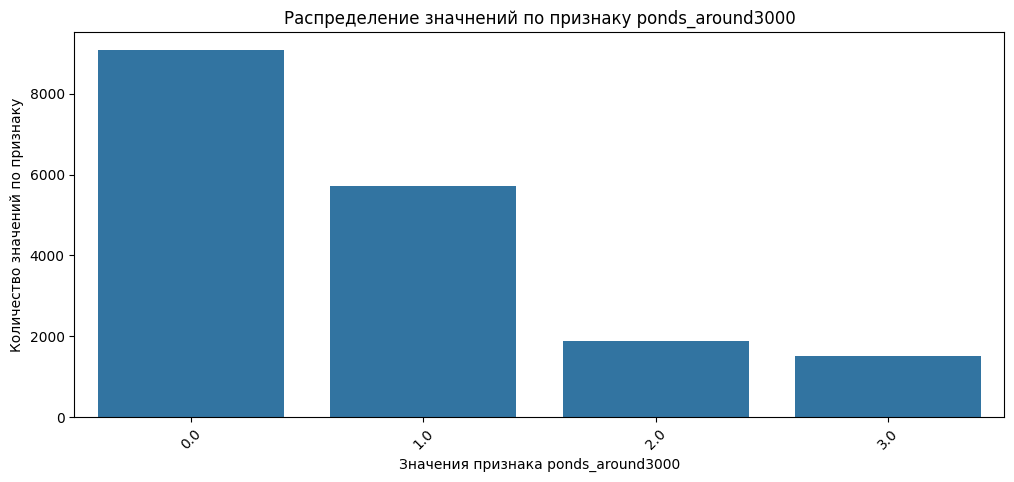

In [11]:
# построение визуализации дискретных количественных показателей
discr_features = ['total_images',
                  'rooms',
                  'floors_total',
                  'floor',
                  'is_apartment',
                  'studio',
                  'open_plan',
                  'balcony',
                  'parks_around3000',
                  'ponds_around3000']

for feature in discr_features:
    discr_distribution(feature)

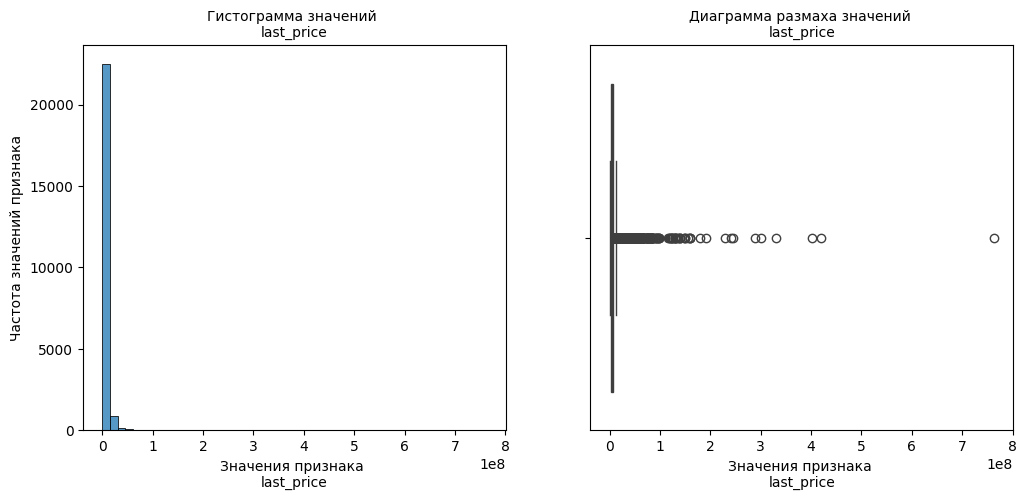

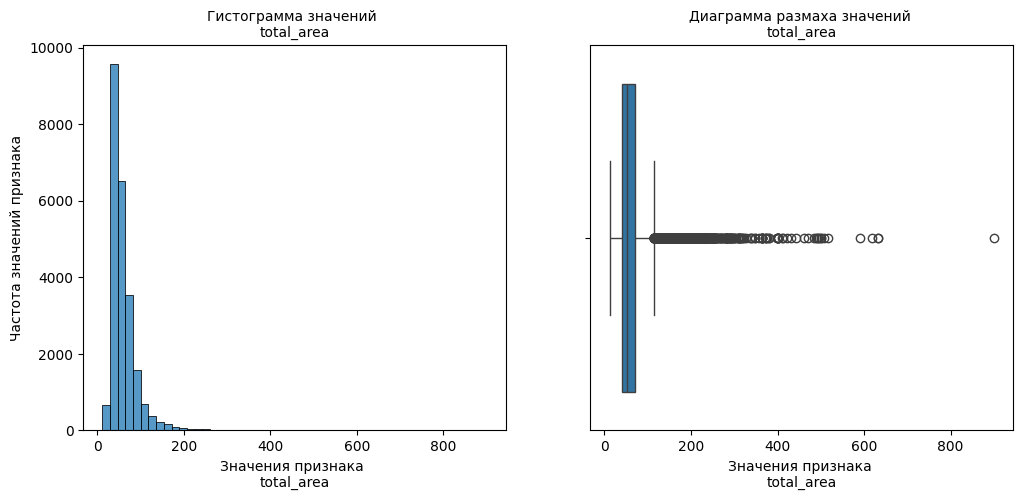

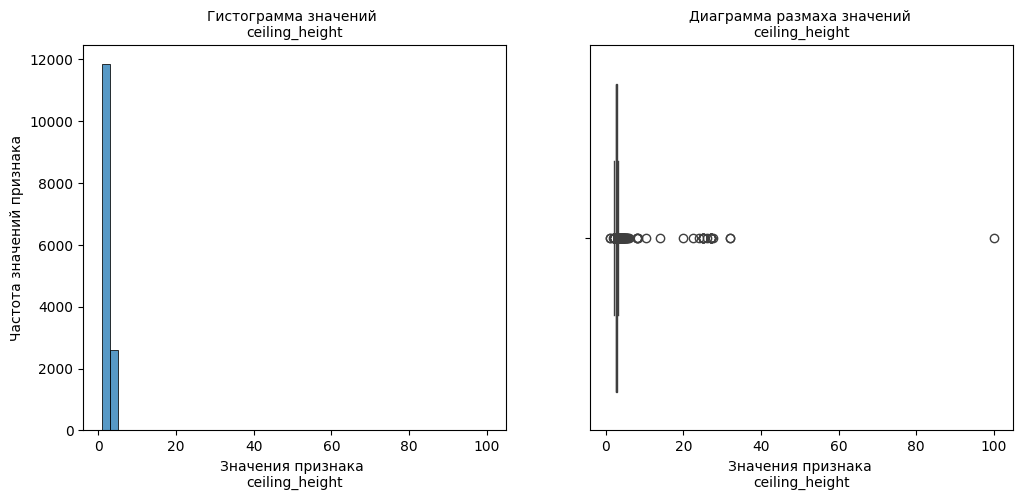

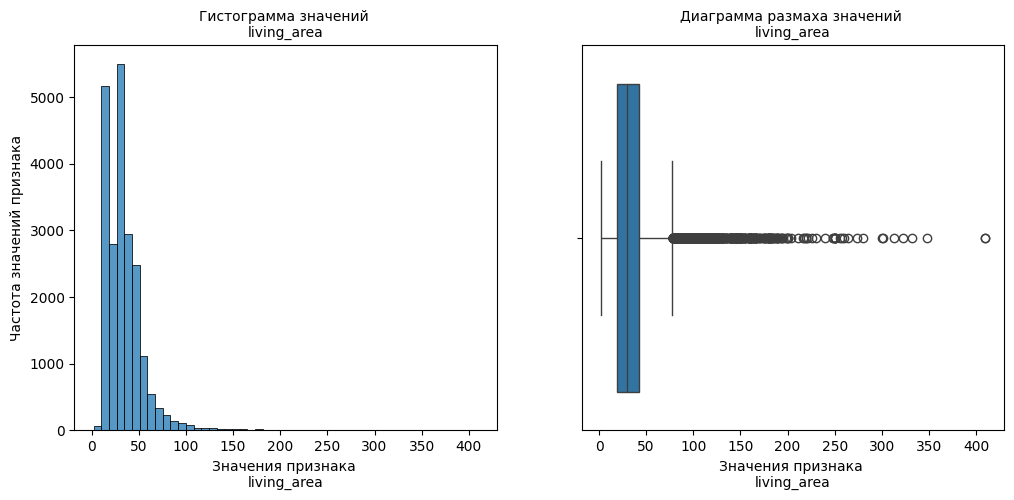

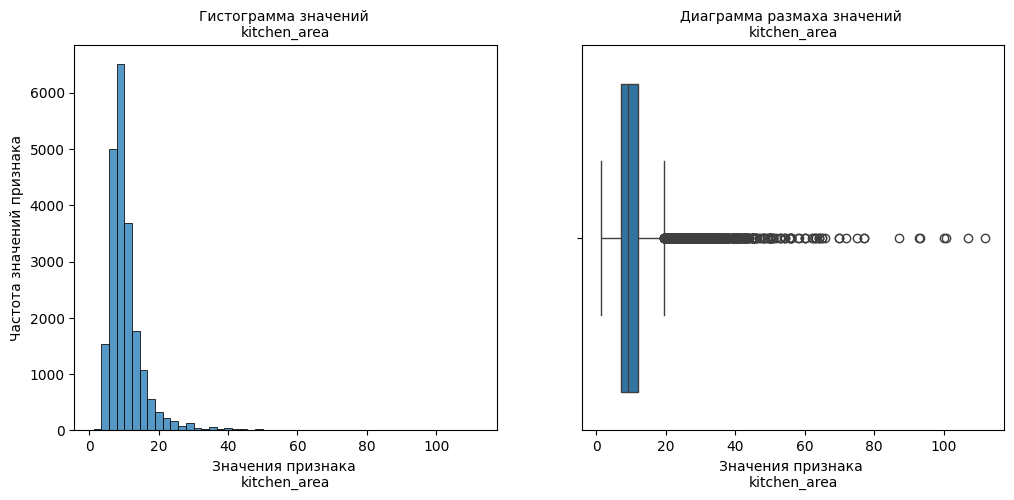

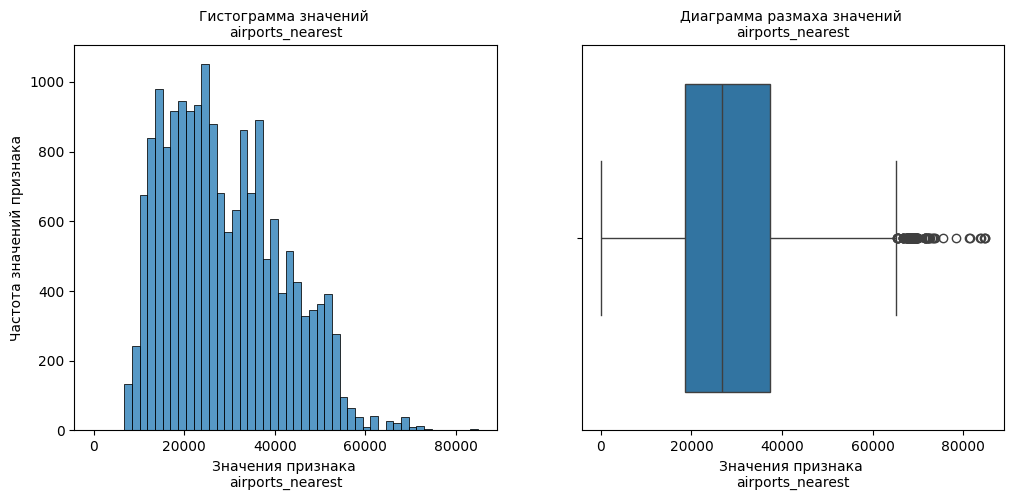

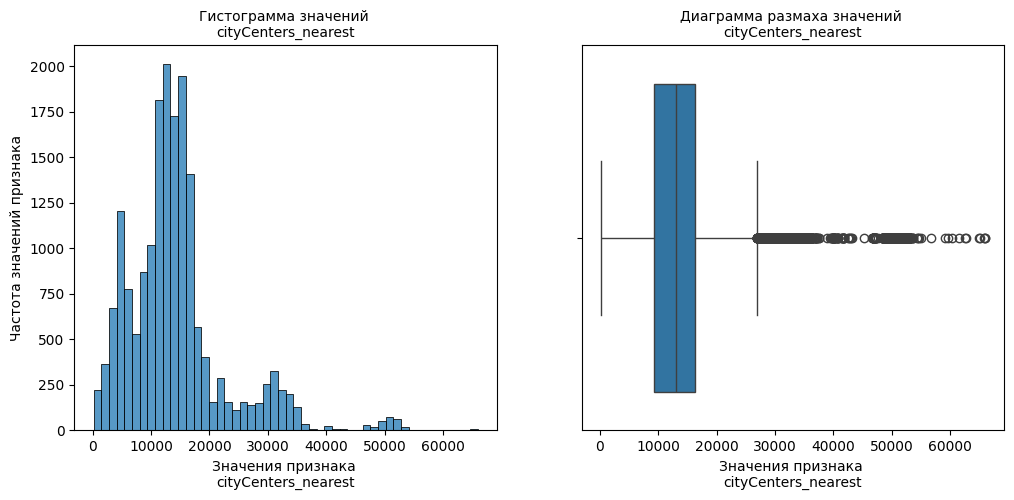

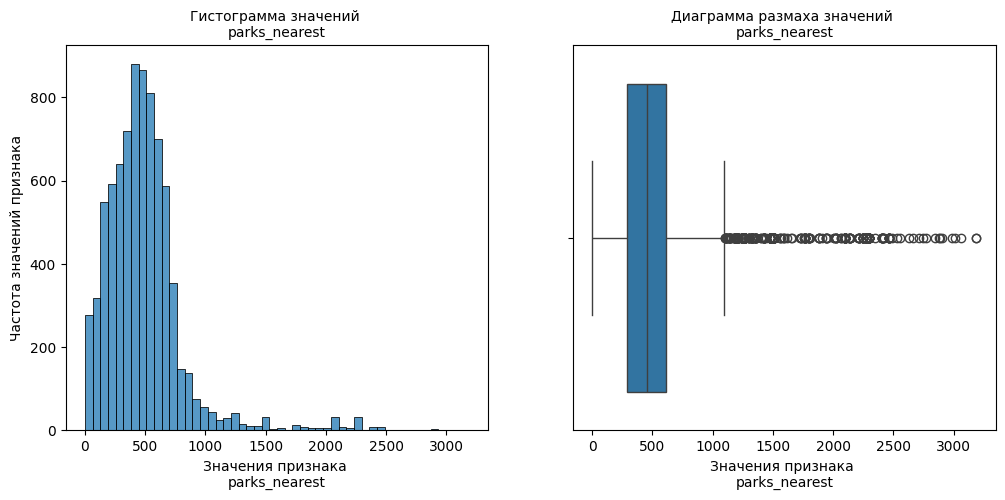

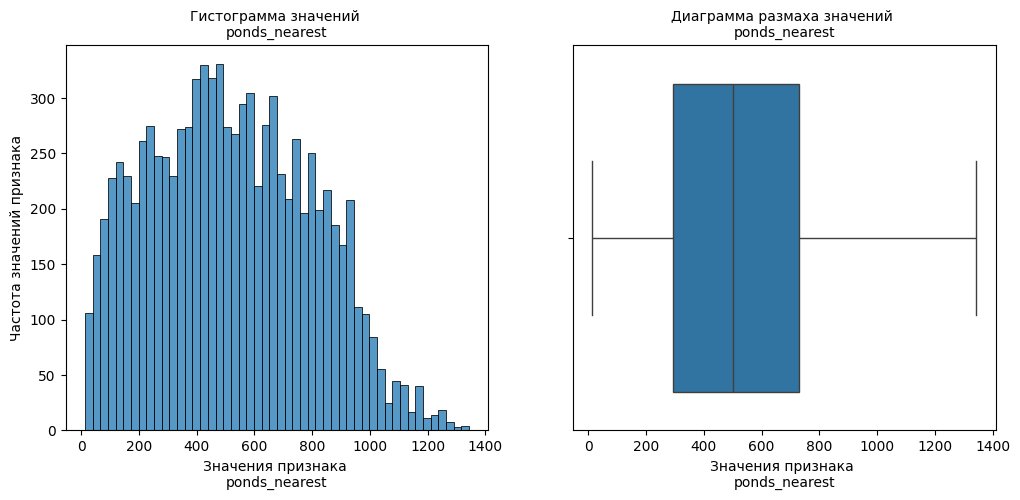

In [12]:
# построение визуализации непрерывных количественных показателей
num_features = ['last_price',
                'total_area',
                'ceiling_height',
                'living_area',
                'kitchen_area',
                'airports_nearest',
                'cityCenters_nearest',
                'parks_nearest',
                'ponds_nearest']

for feature in num_features:
    num_distribution(feature, 50)

<a id="section-4"></a>

## Предобработка данных

In [13]:
df = data.copy()

# Еще раз посмотрим на пропущенные значения, вызвав метод .isna() и просуммировав количество пропусков в
# каждом из столбцов
df.isna().sum().sort_values(ascending = False)

is_apartment            20924
parks_nearest           15620
ponds_nearest           14589
balcony                 11519
ceiling_height           9195
airports_nearest         5542
cityCenters_nearest      5519
ponds_around3000         5518
parks_around3000         5518
days_exposition          3181
kitchen_area             2278
living_area              1903
floors_total               86
locality_name              49
total_images                0
last_price                  0
studio                      0
floor                       0
rooms                       0
first_day_exposition        0
total_area                  0
open_plan                   0
dtype: int64

Больше всего пропусков в столбце **"is_apartment" - "Апартаменты"**, поэтому с него и начнем.

Можно предположить, что при заполнении данных пользователь просто не стал указывать тип жилья, если оно не является апартаментами (если у него апартаменты, то указал 1 или "True". В противном случае, просто пропустил вопрос). Учитывая вводную о том, что это булев тип данных, то заменим пропуски на False и сразу же проверим исправление:

In [14]:
# применим метод fillna() для замены пропусков и выведем после исправлния уникальные значения столбца
df['is_apartment'] = df['is_apartment'].fillna(False)

В описании к задаче говорилось, что можно заполнить пропуски в категории "Балконы" нулевым значением, так как человек мог просто его не указывать (по примеру апартаментов). Выведем все уникальные значения в категории "Балконы", изучим их и заполним пропуски значением "0".

In [15]:
# заполним пропуски значением "0" и преобразуем значения в целочисленный тип
df['balcony'] = df['balcony'].fillna(0).astype(int)

Проверим высоту потолков в столбце **"ceiling_height"**. В массовой типовой многоквартирной застройке (в рассматриваемых данных нет частных домов) высота потолков зависит от климатической зоны и не может быть ниже 2,5 м или 2,7 м. Значения в датасете должны быть в массе своей равны 2.5 метрам - если это так, то пропуски в данном столбце заменим медианным значением:

Text(0.5, 0, 'Высота потолка')

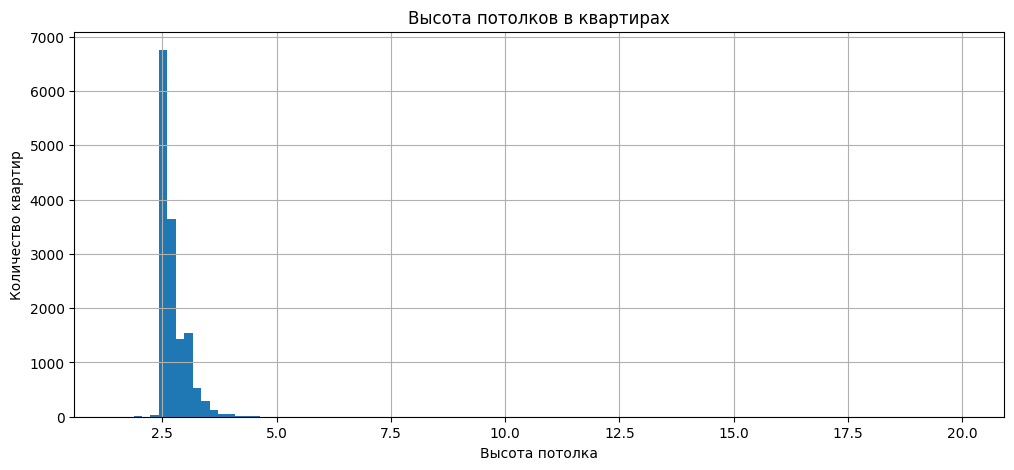

In [16]:
# воспользуемся гистограммой для определения высоты потолков в квартирах
df['ceiling_height'].hist(bins=100, range=(1.5, 20))
plt.title('Высота потолков в квартирах')
plt.ylabel('Количество квартир')
plt.xlabel('Высота потолка')

Отлично! Большая часть значений распределены вокруг значения "2.5", следовательно можно быть уверенным в том, что заменить пропуски медианой будет верным решением. Хоть есть несколько значений с высотой потолка менее 2.5 метров, но эти данные изменить или удалить мы не имеем права.

In [17]:
df['ceiling_height'] = df['ceiling_height'].fillna(df['ceiling_height'].median())

Проверим нулевые значения в столбце "rooms", означающий количество комнат в квартире, и сверим их с тем фактом, не является ли квартира без комнат студией.

In [18]:
df[(df['rooms'] == 0) & (df['studio'] == False)].count()

total_images            59
last_price              59
total_area              59
first_day_exposition    59
rooms                   59
ceiling_height          59
floors_total            59
living_area             55
floor                   59
is_apartment            59
studio                  59
open_plan               59
kitchen_area             0
balcony                 59
locality_name           59
airports_nearest        31
cityCenters_nearest     31
parks_around3000        31
parks_nearest            9
ponds_around3000        31
ponds_nearest           21
days_exposition         59
dtype: int64

Из 23 699 строк с данными 59 строк оказались с ошибкой: не было указано количество комнат, и данная жилая площадь не является студией. Исправим это присвоив статус таким квартирам "студия", указав True в столбце "studio".

In [19]:
df.loc[df['rooms'] == 0, 'studio'] = True
# проверим выполнение исправления
df[(df['rooms'] == 0) & (df['studio'] == False)]

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition


Ошибка в данных исправлена, поэтому можно двигаться дальше.

Заполним пустые значения по площади кухни и жилой площади.
Для начала построим гистограмму, чтобы увидеть, как варьируются жилые площади и площади кухонь в объявлениях датасета:

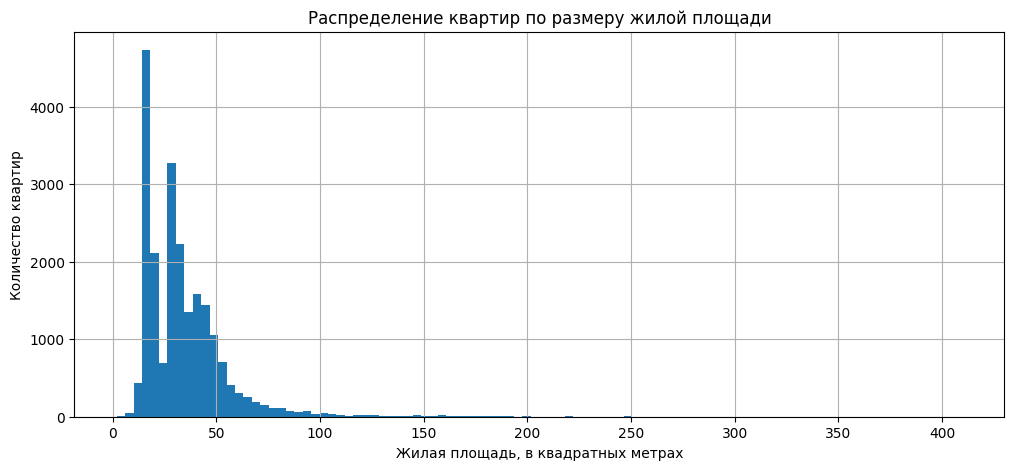

count    21796.000000
mean        34.457852
std         22.030445
min          2.000000
25%         18.600000
50%         30.000000
75%         42.300000
max        409.700000
Name: living_area, dtype: float64


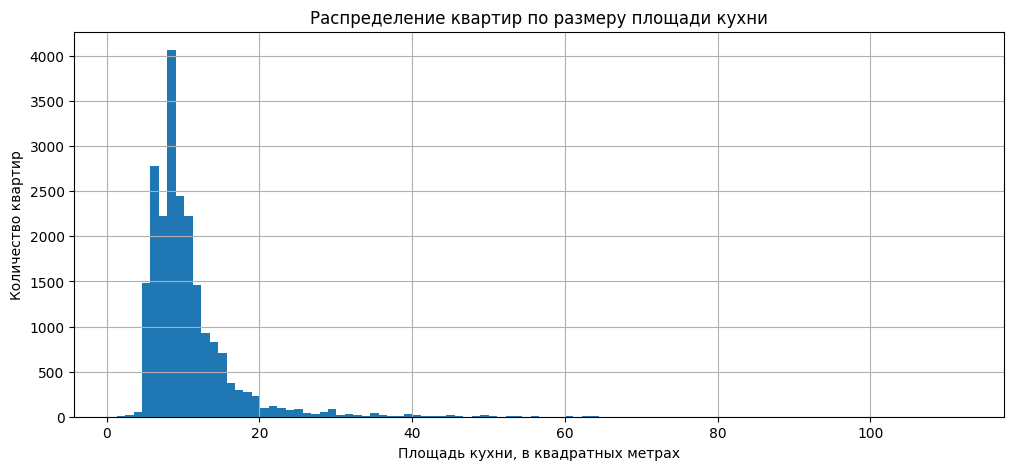

count    21421.000000
mean        10.569807
std          5.905438
min          1.300000
25%          7.000000
50%          9.100000
75%         12.000000
max        112.000000
Name: kitchen_area, dtype: float64


In [20]:
df['living_area'].hist(bins=100)
plt.title('Распределение квартир по размеру жилой площади')
plt.ylabel('Количество квартир')
plt.xlabel('Жилая площадь, в квадратных метрах')
plt.show()
print(df['living_area'].describe())
df['kitchen_area'].hist(bins=100)
plt.title('Распределение квартир по размеру площади кухни')
plt.ylabel('Количество квартир')
plt.xlabel('Площадь кухни, в квадратных метрах')
plt.show()
print(df['kitchen_area'].describe())

Как видно из данных, полученных с помощью метода describe(), медианное значение жилой площади составляет 30 квадратных метров. Можно было бы заполнить все пропуски именно этим значением, но такая жилая площадь характерная однокомнатным квартирам. Следовательно, чтобы правильно заполнить пропуски, необходимо найти отношения жилой площади и площади кухни к общей площади квартиры, и умножить получившиеся коэффициенты на общие площади квартир с пропусками:

In [21]:
# Заменяем пустые значения жилой площади и площади кухни
living_ratio = df['living_area'].mean() / df['total_area'].mean()
kitchen_ratio = df['kitchen_area'].mean() / df['total_area'].mean()
df['living_area'] = df['living_area'].fillna(living_ratio * df['total_area'])
df['kitchen_area'] = df['kitchen_area'].fillna(kitchen_ratio * df['total_area'])

Дальше заменим пустые значения в количестве парков и прудов в районе 3 км. Возможно, человек, разместивший объявление, решил просто не указывать, есть ли поблизости парки и пруды, поэтому посчитаем, что все пропуски - это знак того, что подобных объектов поблизости нет.

In [22]:
# Посмотрим уникальные значения в столбцах с количеством парков и прудов
print(df['parks_around3000'].unique())
print(df['ponds_around3000'].unique())
# Приводим в целочисленный тип количество парков. Заменяем пропущенные значения на 0
df['parks_around3000'] = df['parks_around3000'].fillna(value=0).astype(int)
# Приводим в целочисленный тип количество прудов. Заменяем пропущенные значения на 0
df['ponds_around3000'] = df['ponds_around3000'].fillna(value=0).astype(int)

[ 1.  0.  2. nan  3.]
[ 2.  0.  3.  1. nan]


Увы, но мы никак не сможем уточнить этажность в доме...Если только есть возможность связаться с хозяевами квартир, которые не указали этажность в доме) Так как мы имеем дело только с набором данных, а количество позциий, где не указана этажность, ничтожно мало, то можно просто от них избавиться - удалим эти строки из датасета:

In [23]:
df = df.dropna(subset = ['floors_total']).reset_index(drop=True)
# приведем количество этажей в здании к целочисленному типу
df['floors_total'] = df['floors_total'].astype(int)

Последние из имеющихся пропусков находятся в столбце "locality_name". Так как место нахождения квартиры понадобится для определения ее стоимости, а пропусков в рассматриваемом столбце ничтожно мало по сравнению с общим размером датафрейма, то мы вправе удалить данные строки вместо того, чтобы пытаться установить расположение квартиры.

In [24]:
df = df.dropna(subset = ['locality_name']).reset_index(drop = True)

Проверяем пропуски после всех проведенных действий.

In [25]:
df.isna().sum().sort_values(ascending = False)

parks_nearest           15535
ponds_nearest           14529
airports_nearest         5524
cityCenters_nearest      5501
days_exposition          3171
last_price                  0
ponds_around3000            0
parks_around3000            0
locality_name               0
balcony                     0
kitchen_area                0
total_images                0
studio                      0
is_apartment                0
floor                       0
living_area                 0
floors_total                0
ceiling_height              0
rooms                       0
first_day_exposition        0
total_area                  0
open_plan                   0
dtype: int64

### Выводы:
1. Пропуски в данных изучены и заполнены, ошибки исправлены. Можно двигаться дальше;
2. Категории, где не удалось заполнить пропуски, следующие:
    а) 'airports_nearest';
    б) 'cityCenters_nearest';
    в) 'days_exposition';
    г) 'parks_nearest';
    д) 'ponds_nearest'

Мы не сможем точно сказать, какое расстояние до парков и прудов, сколько дней просуществовало объявление о продаже, а так же не сможем сказать на каком расстоянии находится аэропорт или торговый центр. Эти все параметры можно уточнить только если сами займемся исследованием местоположения каждой квартиры, но в условии задачи такого пункта нет.

<a id="section-5"></a>

## Расчёты и добавление результатов в таблицу

Первый из необходимых расчетов - **расчет цены одного квадратного метра**. Сделать его будет достаточно просто: необходимо поделить значения столбца "last_price" на значения столбца "total_area" и присвоить получившиеся значения новому столбцу.

Пролистывать весь датафрейм для просмотра значений в новом столбце не очень-то и удобно - добавим его после столбца "total_area" со значениями площади, чтобы была видна взаимосвязь с исходными данными для расчета цены за квадратный метр.

In [26]:
df.insert(3, 'price_per_square', round(df['last_price'] / df['total_area'], 1))
display(df.head())

,total_images,last_price,total_area,price_per_square,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,13000000.0,108.0,120370.4,2019-03-07T00:00:00,3,2.70,16,51.000000,8,...,25.000000,0,Санкт-Петербург,18863.0,16028.0,1,482.0,2,755.0,NaN
1,7,3350000.0,40.4,82920.8,2018-12-04T00:00:00,1,2.65,11,18.600000,1,...,11.000000,2,посёлок Шушары,12817.0,18603.0,0,NaN,0,NaN,81.0
2,10,5196000.0,56.0,92785.7,2015-08-20T00:00:00,2,2.65,5,34.300000,4,...,8.300000,0,Санкт-Петербург,21741.0,13933.0,1,90.0,2,574.0,558.0
3,0,64900000.0,159.0,408176.1,2015-07-24T00:00:00,3,2.65,14,90.785766,9,...,27.848168,0,Санкт-Петербург,28098.0,6800.0,2,84.0,3,234.0,424.0
4,2,10000000.0,100.0,100000.0,2018-06-19T00:00:00,2,3.03,14,32.000000,13,...,41.000000,0,Санкт-Петербург,31856.0,8098.0,2,112.0,1,48.0,121.0


В описании задания сказано, что необходимо добавить в датафрейм день недели, месяц и год публикации объявления о жилой площади. Этим и займемся:

In [27]:
# сперва переведем столбец "first_day_exposition" в формат даты
df['first_day_exposition'] = pd.to_datetime(df['first_day_exposition'])
# добавим столбец с днем недели после столбца "first_day_exposition"
df.insert(5, 'day_of_week', df['first_day_exposition'].dt.day_name())
# добавим столбцы с месяцем и годом после созданного столбца с днем недели - "day_of_week"
df.insert(6, 'month_exposition', df['first_day_exposition'].dt.month)
df.insert(7, 'year_exposition', df['first_day_exposition'].dt.year)

Далее, присвоим статусы этажам: "Первый", "Последний", Другой".

In [28]:
df.loc[df['floor'] == 1, 'floor_category'] = 'Первый'
df.loc[df['floor'] == df['floors_total'], 'floor_category'] = 'Последний'
df.loc[df['floor_category'].isna(), 'floor_category'] = 'Другой'

Найдем соотношения жилой площади к общей площади и отношение площади кухни к общей площади помещений

In [29]:
df['living_area_ratio'] = round(df['living_area'] / df['total_area'], 2)
df['kitchen_area_ratio'] = round(df['kitchen_area'] / df['total_area'], 2)

Посмотрим на преобразования, вызвав функцию display()

In [30]:
display(df.head())

,total_images,last_price,total_area,price_per_square,first_day_exposition,day_of_week,month_exposition,year_exposition,rooms,ceiling_height,...,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition,floor_category,living_area_ratio,kitchen_area_ratio
0,20,13000000.0,108.0,120370.4,2019-03-07,Thursday,3,2019,3,2.70,...,18863.0,16028.0,1,482.0,2,755.0,NaN,Другой,0.47,0.23
1,7,3350000.0,40.4,82920.8,2018-12-04,Tuesday,12,2018,1,2.65,...,12817.0,18603.0,0,NaN,0,NaN,81.0,Первый,0.46,0.27
2,10,5196000.0,56.0,92785.7,2015-08-20,Thursday,8,2015,2,2.65,...,21741.0,13933.0,1,90.0,2,574.0,558.0,Другой,0.61,0.15
3,0,64900000.0,159.0,408176.1,2015-07-24,Friday,7,2015,3,2.65,...,28098.0,6800.0,2,84.0,3,234.0,424.0,Другой,0.57,0.18
4,2,10000000.0,100.0,100000.0,2018-06-19,Tuesday,6,2018,2,3.03,...,31856.0,8098.0,2,112.0,1,48.0,121.0,Другой,0.32,0.41


**Вывод**: все действия в шаге 3 выполнены.

<a id="section-6"></a>

## Исследовательский анализ данных

Начинаем с работы с редкими и выбивающимися значениями

In [31]:
# Функция для подсчёта границ с учетом 1.5 размаха
def quartile_range(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    dfq = df.loc[(df[column] < q3 + 1.5*iqr) & (df[column] > q1 - 1.5*iqr), column]
    return dfq
# Столбцы с выбросами
list_features = ['last_price', 'total_area', 'kitchen_area', 'living_area', 'days_exposition', 'ceiling_height', 'rooms']
for col in list_features:
    df[col] = quartile_range(df, col)

# Возвращаем в целочисленный тип число комнат
df['rooms'] = df['rooms'].fillna(0).astype(int)

# Изучаем, есть ли выбивающиеся значения
df.describe()

,total_images,last_price,total_area,price_per_square,first_day_exposition,month_exposition,year_exposition,rooms,ceiling_height,floors_total,...,balcony,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition,living_area_ratio,kitchen_area_ratio
count,23565.000000,2.151900e+04,22326.000000,2.356500e+04,23565,23565.000000,23565.000000,23565.000000,20601.000000,23565.000000,...,23565.000000,18041.000000,18064.000000,23565.000000,8030.000000,23565.000000,9036.000000,18721.000000,23565.000000,23565.000000
mean,9.878421,4.837115e+06,54.319704,9.940584e+04,2017-11-10 08:59:53.125398016,6.401570,2017.371016,2.013495,2.631089,10.675875,...,0.593677,28797.082701,14192.656056,0.468831,490.580448,0.589900,518.289509,128.299343,0.565318,0.186617
min,0.000000,1.219000e+04,12.000000,1.118000e+02,2014-11-27 00:00:00,1.000000,2014.000000,0.000000,2.460000,1.000000,...,0.000000,0.000000,181.000000,0.000000,1.000000,0.000000,13.000000,1.000000,0.020000,0.030000
25%,6.000000,3.300000e+06,39.400000,7.656610e+04,2017-05-15 00:00:00,3.000000,2017.000000,1.000000,2.600000,5.000000,...,0.000000,18565.000000,9238.000000,0.000000,288.000000,0.000000,293.000000,41.000000,0.500000,0.140000
50%,9.000000,4.400000e+06,50.000000,9.500000e+04,2017-12-12 00:00:00,6.000000,2017.000000,2.000000,2.650000,9.000000,...,0.000000,26757.000000,13096.500000,0.000000,455.000000,0.000000,503.000000,85.000000,0.570000,0.180000
75%,14.000000,6.000000e+06,65.500000,1.142132e+05,2018-08-26 00:00:00,10.000000,2018.000000,3.000000,2.650000,16.000000,...,1.000000,37273.000000,16285.000000,1.000000,612.000000,1.000000,730.000000,182.000000,0.630000,0.220000
max,50.000000,1.186686e+07,114.200000,1.907500e+06,2019-05-03 00:00:00,12.000000,2019.000000,5.000000,2.850000,60.000000,...,5.000000,84869.000000,65968.000000,3.000000,3190.000000,3.000000,1344.000000,509.000000,1.000000,0.790000
std,5.681156,2.215774e+06,19.331030,5.038943e+04,NaN,3.492948,1.037393,0.986750,0.081473,6.594823,...,0.960660,12632.499735,8613.348153,0.748403,341.572956,0.883966,278.009558,121.064671,0.101125,0.069585


### Принимаемся за изучение следующих параметров: площадь, цена, число комнат, высота потолков.
Для этого построим гистограммы с визуализацией каждого параметра:

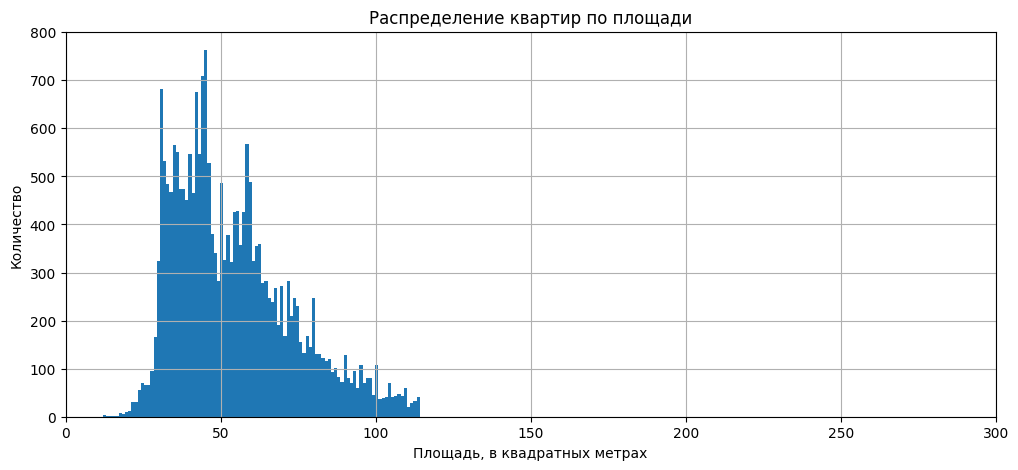

Объявления квартир с наибольшей площадью:


5947     114.2
18916    114.2
1165     114.2
4635     114.2
20363    114.2
5823     114.1
18020    114.0
6428     114.0
19850    114.0
8208     114.0
Name: total_area, dtype: float64

In [32]:
df['total_area'].hist(bins=100)
plt.title('Распределение квартир по площади')
plt.ylabel('Количество')
plt.xlabel('Площадь, в квадратных метрах')
# при первом исполнении данного кода ось абсцисс автоматически ограничивалась значением "800".
# ограничим гистограмму по оси абсцисс значением "300"
plt.xlim(0, 300)
plt.show()
print('Объявления квартир с наибольшей площадью:')
display(df['total_area'].sort_values(ascending=False).head(10))

Теперь сравним цены на квартиры по примеру предыдущего пункта со сравнением площадей:

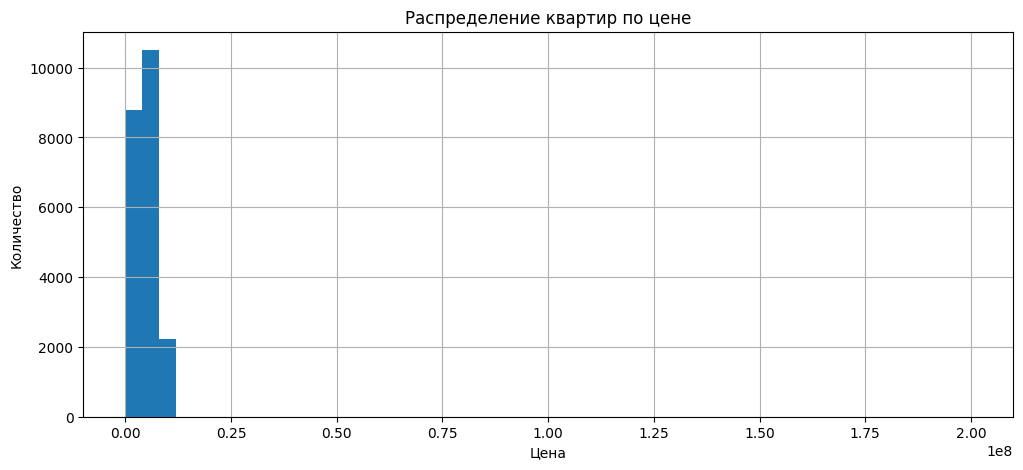

Объявления квартир с наибольшей стоимостью:


3151     11866860.0
21736    11858000.0
12366    11850000.0
10016    11840000.0
19345    11820000.0
20081    11809670.0
22201    11800000.0
3626     11800000.0
2498     11800000.0
2259     11800000.0
Name: last_price, dtype: float64

count    2.151900e+04
mean     4.837115e+06
std      2.215774e+06
min      1.219000e+04
25%      3.300000e+06
50%      4.400000e+06
75%      6.000000e+06
max      1.186686e+07
Name: last_price, dtype: float64


In [33]:
df['last_price'].hist(bins=50, range=(0, 200000000))
plt.title('Распределение квартир по цене')
plt.ylabel('Количество')
plt.xlabel('Цена')
plt.show()
print('Объявления квартир с наибольшей стоимостью:')
display(df['last_price'].sort_values(ascending=False).head(10))
print(df['last_price'].describe())

Строим гистограмму для параметра "число комнат":

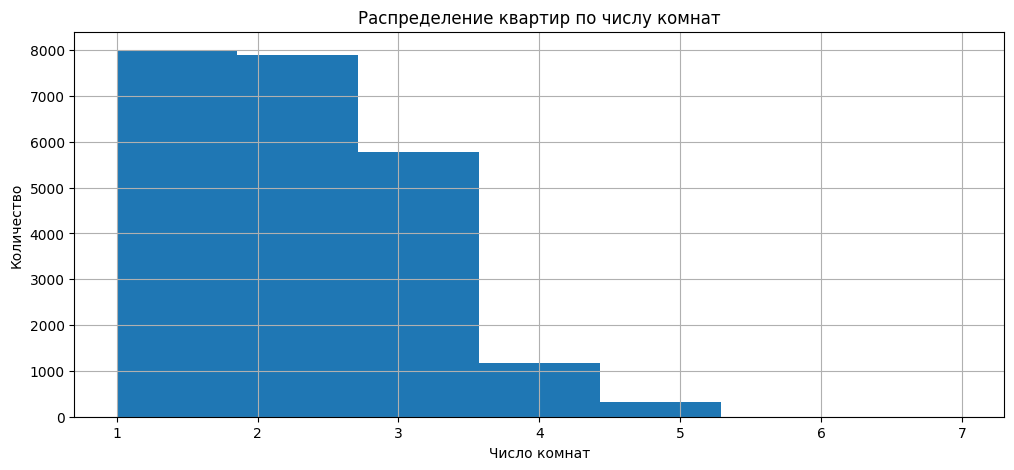

Объявления квартир с наибольшим количеством комнат:


18345    5
5490     5
23173    5
13065    5
333      5
7759     5
2129     5
3253     5
10956    5
10418    5
Name: rooms, dtype: int64

In [34]:
df['rooms'].hist(bins=7, range=(1, 7))
plt.title('Распределение квартир по числу комнат')
plt.ylabel('Количество')
plt.xlabel('Число комнат')
plt.show()
print('Объявления квартир с наибольшим количеством комнат:')
display(df['rooms'].sort_values(ascending=False).head(10))

Последняя диаграмма для параметра "Высота потолков":

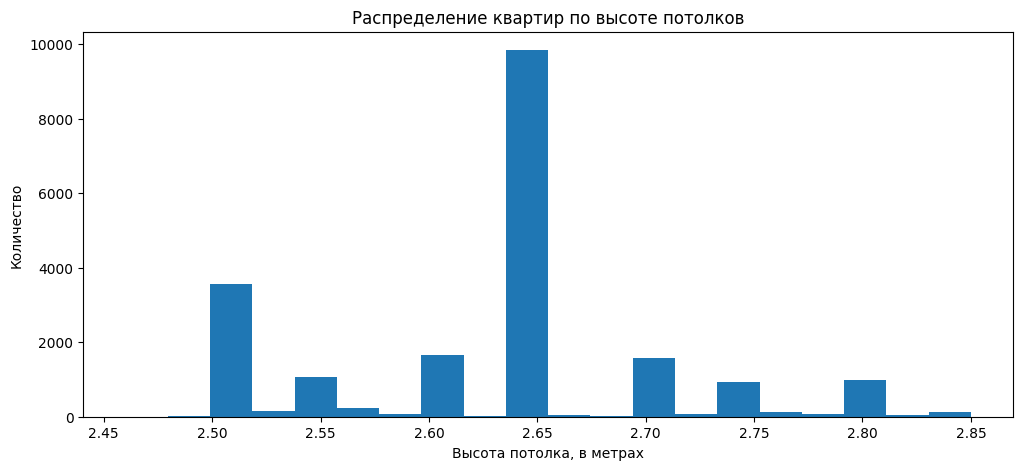

1373     2.85
147      2.85
15508    2.85
5407     2.85
3669     2.85
17072    2.85
10406    2.85
16168    2.85
2204     2.85
10975    2.85
Name: ceiling_height, dtype: float64

In [35]:
plt.hist(df.query('(ceiling_height > 2) & (ceiling_height < 4)')['ceiling_height'], bins=20)
plt.title('Распределение квартир по высоте потолков')
plt.ylabel('Количество')
plt.xlabel('Высота потолка, в метрах')
plt.show()
display(df['ceiling_height'].sort_values(ascending=False).head(10))

**Выводы:**
1. Большая часть квартир (по площади) находится в пределах 100 квадратных метров. Имеются "выбросы" значений в районе значений площади 300 квадратных метров;
2. В большинстве случаев стоимость квартир составляет около 5 миллионов рублей. Есть варианты со стоимостью более 20 миллионов рублей, но таких вариантов мало. Есть единичные объявления, где указанная стоимость более 100 миллионов рублей;
3. В большинстве объявлений квартиры предлагаются с числом комнат до трех включительно. Есть варианты квартир с количеством комнат, равным семи;
4. В категории "высота потолка" большинство квартир имеют высоту, приближенную к 2,75 метрам;

### Строим гистограмму с отображением времени продажи квартиры

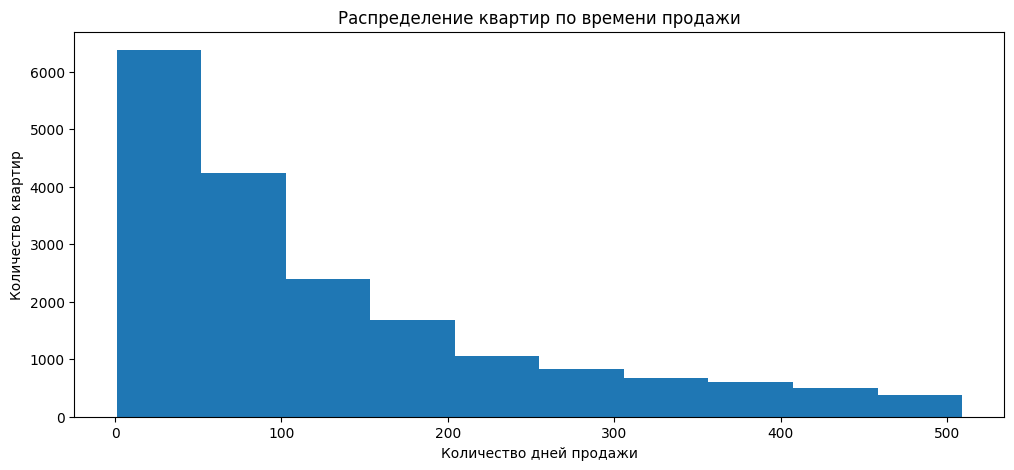

count    18721.000000
mean       128.299343
std        121.064671
min          1.000000
25%         41.000000
50%         85.000000
75%        182.000000
max        509.000000
Name: days_exposition, dtype: float64

In [36]:
plt.hist(df['days_exposition'])
plt.title('Распределение квартир по времени продажи')
plt.ylabel('Количество квартир')
plt.xlabel('Количество дней продажи')
plt.show()
# метод describe() поможет дать ответ на вопросы о скором и долгом времени продажи
df['days_exposition'].describe()

**Вывод:**
В большинстве случаев квартиры продают за 95 дней, однако среднее время продажи составляет 181 день.
Исходя из данных, полученных методом describe(), можно сказать, что быстрой продажей можно назвать сделки завершенные **до 45 дней**, а долгие продажи - сделки, совершенные за более чем 231 дней (это около 7,7 месяцев).

### Изучаем факторы, влияющие на стоимость квартиры

Построим для каждого сравнения графики корреляции и сгруппируем данные в сводные таблицы.

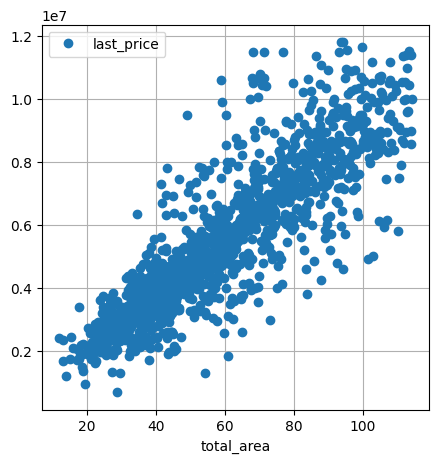

Корреляция цены и площади: 

            last_price  total_area
last_price    1.000000    0.905372
total_area    0.905372    1.000000 



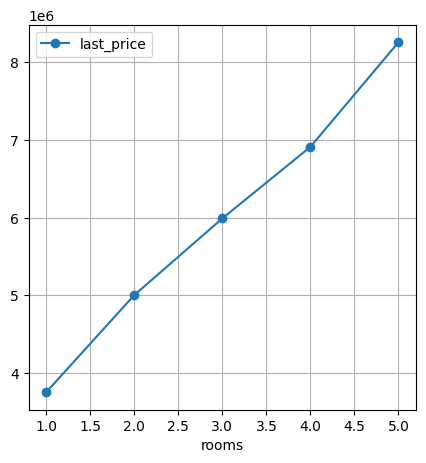

Корреляция цены и числа комнат: 

            last_price     rooms
last_price    1.000000  0.537551
rooms         0.537551  1.000000 



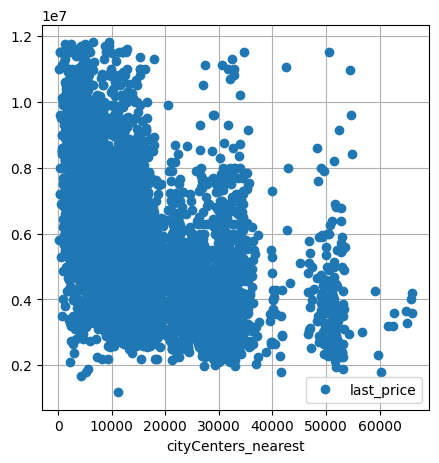

Корреляция цены и удалённости от центра: 

                     cityCenters_nearest  last_price
cityCenters_nearest             1.000000    0.712077
last_price                      0.712077    1.000000 



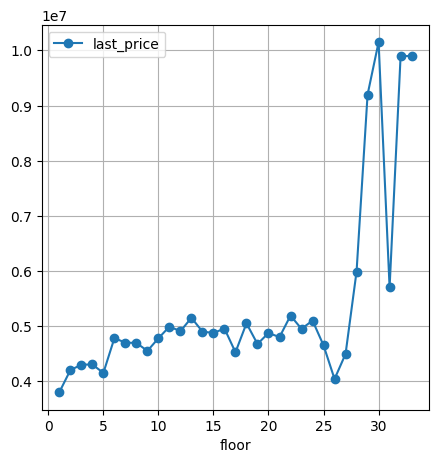

In [37]:
# Зависимость цены от площади
(
    df.pivot_table(index='total_area', values='last_price')
    .plot(grid=True, style='o', figsize=(5, 5))
)
plt.show()
print('Корреляция цены и площади:','\n')
print(df.pivot_table(index='floor', values=['total_area', 'last_price']).corr(),'\n')

# Зависимость цены от числа комнат
(
    df.query('rooms > 0').pivot_table(index='rooms', values='last_price')
    .plot(grid=True, style='o-', figsize=(5, 5))
)
plt.show()
print('Корреляция цены и числа комнат:','\n')
print(df.query('rooms > 0').pivot_table(index='floor', values=['rooms', 'last_price']).corr(),'\n')

# Зависимость цены от удалённости от центра
(
    df.pivot_table(index='cityCenters_nearest', values='last_price')
    .plot(grid=True, style='o', figsize=(5, 5))
)
plt.show()
print('Корреляция цены и удалённости от центра:','\n')
print(df.pivot_table(index='floor', values=['cityCenters_nearest', 'last_price']).corr(),'\n')

# Зависимость цены от этажа
(
    df.pivot_table(index='floor', values='last_price', aggfunc='median')
    .plot(grid=True, style='o-', figsize=(5, 5))
)
plt.show()

**Выводы:**
1. Чем больше **площадь**, тем выше стоимость. Корреляция этих параметров крайне высокая;

2. Число комнат влияет на цену (больше комнат - больше цена), однако зависимость ниже, чем у площади. Можно сделать два вывода: бывают квартиры с большими по площади комнатами; квартиры в центре состоят из малого числа комнат, но стоят достаточно высоко.

3. Самые дорогие варианты квартир находятся в центре города, однако в центре также есть и достаточно дешёвые варианты.

4. Первый этаж непосредственно влияет на стоимость квартиры - в среднем квартиры на 1-м этаже значительно дешевле. Чуть дороже последний этаж. Наибольшая стоимость у квартир, расположенных не на 1-м и не на последнем этаже.

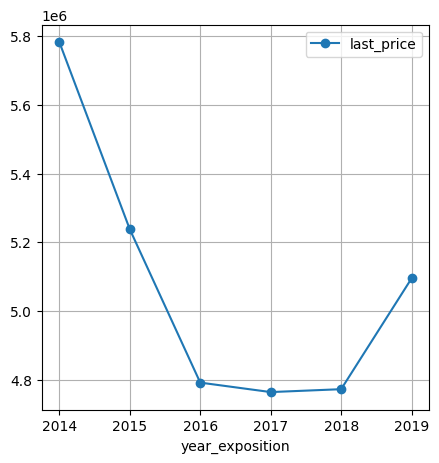

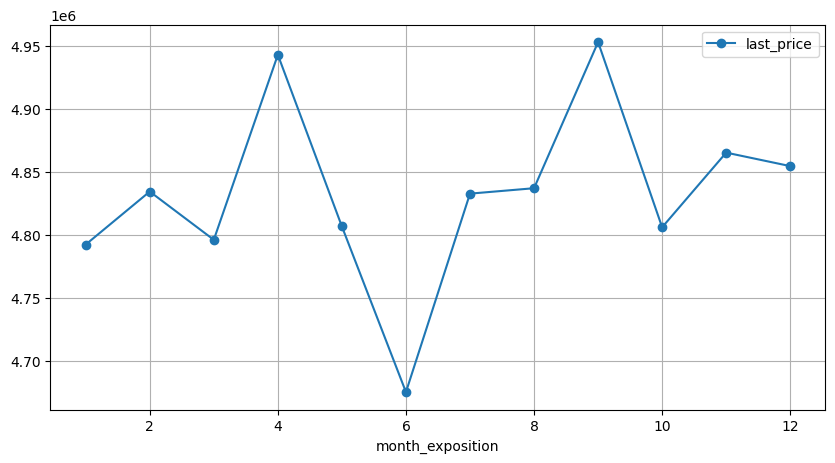

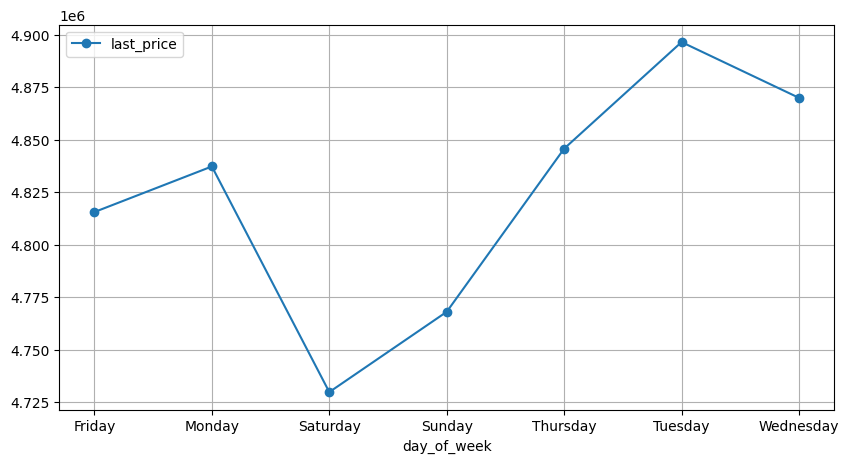

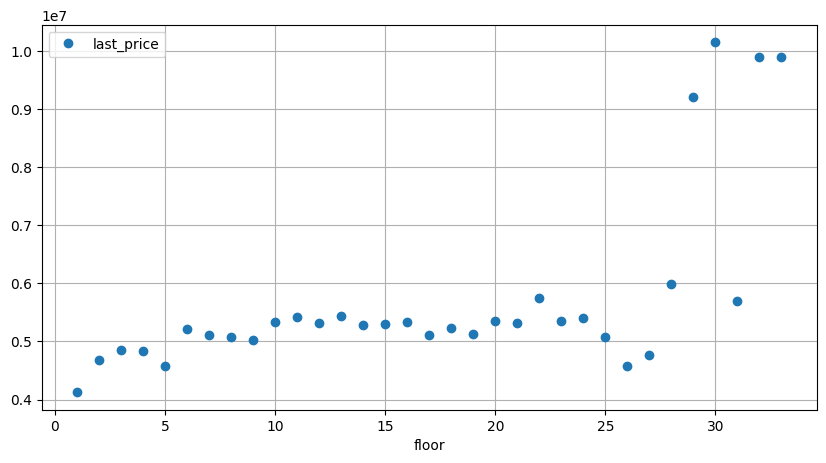

Корреляция цены и этажа: 

              floor  last_price
floor       1.00000    -0.05089
last_price -0.05089     1.00000 



In [38]:
# Зависимость цены от года размещения
(
    df.pivot_table(index='year_exposition', values='last_price')
    .plot(grid=True, style='o-', figsize=(5, 5))
)

# Зависимость цены от месяца размещения
(
    df.pivot_table(index='month_exposition', values='last_price')
    .plot(grid=True, style='o-', figsize=(10, 5))
)

# Зависимость цены от дня недели размещения объявления
(
    df.pivot_table(index='day_of_week', values='last_price')
    .plot(grid=True, style='o-', figsize=(10, 5))
)

# Корреляция цены и этажа
(
    df.pivot_table(index='floor', values='last_price')
    .plot(grid=True, style='o', figsize=(10, 5))
)
plt.show()
print('Корреляция цены и этажа:','\n')
print(df.pivot_table(index='total_area', values=['floor', 'last_price']).corr(),'\n')

**Выводы:**

Год: квартиры очень сильно подешевели в 2016-2018 годах, что, вероятно, вызвано ослаблением курса рубля во время кризиса в 2014 году. В 2019 году цены снова стали повышаться, т.к. ситуация немного стабилизировалась;

Месяц: дороже всего квартиры, продающиеся в сентябре, дешевле всего - в июне;

День недели: дороже всего квартиры, размещенные во вторник, дешле всего - в cубботу;

Этаж: корреляция цены и этажа близка к нулевому значечнию (равна -0.05089), а это значит, что зависимости цены от этажа не наблюдается;

### Выбираем 10 населённых пунктов с наибольшим числом объявлений

In [39]:
# первые десять населенных пунктов по количеству объявлений
ten_cities = df['locality_name'].value_counts().head(10)
display(ten_cities)

locality_name
Санкт-Петербург      15651
посёлок Мурино         520
посёлок Шушары         439
Всеволожск             398
Пушкин                 369
Колпино                338
посёлок Парголово      327
Гатчина                307
деревня Кудрово        299
Выборг                 237
Name: count, dtype: int64

In [40]:
# выведем среднюю цену квадратного метра 
ten_cities_pivot = df.query('locality_name in (@ten_cities.index)').pivot_table(values = 'price_per_square', index='locality_name').sort_values(by='price_per_square',ascending=False)
ten_cities_pivot = ten_cities_pivot.astype(int)
display(ten_cities_pivot)

,price_per_square
locality_name,
Санкт-Петербург,114868
Пушкин,103125
деревня Кудрово,92473
посёлок Парголово,90175
посёлок Мурино,85673
посёлок Шушары,78551
Колпино,75424
Гатчина,68746
Всеволожск,68654


**Выводы:**
Как и ожидалось, в Санкт-Петербурге самая высокая стоимость 1 квадратного метра. Затем идёт Пушкин, что, вероятно, вызвано старинной застройко и большим обилием достопримечательностей и памятников культуры. Затем идут районы, фактически являющиеся Санкт-Петербургом и непосредственно к нему примыкают.
Замыкают ТОП-10 Гатчина, Всеволожск и Выборг.

### Изучаем стоимость квартир в зависимости от расстояния до центра города

<Axes: xlabel='cityCenters_kilometres'>

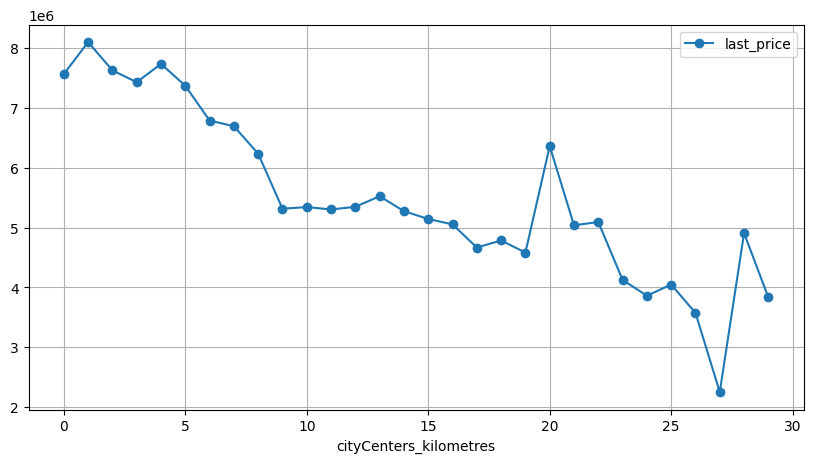

In [41]:
# в исходном датасете создадим столбец с расстояниями от центра в километрах
df['cityCenters_kilometres'] = df['cityCenters_nearest'] / 1000
# заполним пропущенные значения "0", так как если поставим любое другое значение, то это сильно
# исказит конечный график
df['cityCenters_kilometres'] = df['cityCenters_kilometres'].fillna(0).astype(int)
# выделяем квартиры в Санкт-Петербурге и строим график
piters_flats = df.query('locality_name == "Санкт-Петербург"')
(
    piters_flats.pivot_table(index = 'cityCenters_kilometres', values='last_price').
    plot(grid=True, style='o-', figsize=(10,5))
)

**Выводы:**
Закономерно, что цена снижается по мере удаления от центра города. Центральной зоной можно квартиры находящиеся от центра на расстоянии от 0 до 7 километров. Для всех остальных вариантов квартир цена резко падает, что может означать, что они находятся на окраине города.

### Выделяем и изучаем квартиры в центре

In [42]:
piter_centre = piters_flats.query('cityCenters_kilometres <= 7')

Площадь по городу (медиана): 52 

Площадь в центре (медиана): 68 

Площадь по городу (среднее): 56 

Площадь в центре (среднее): 69 



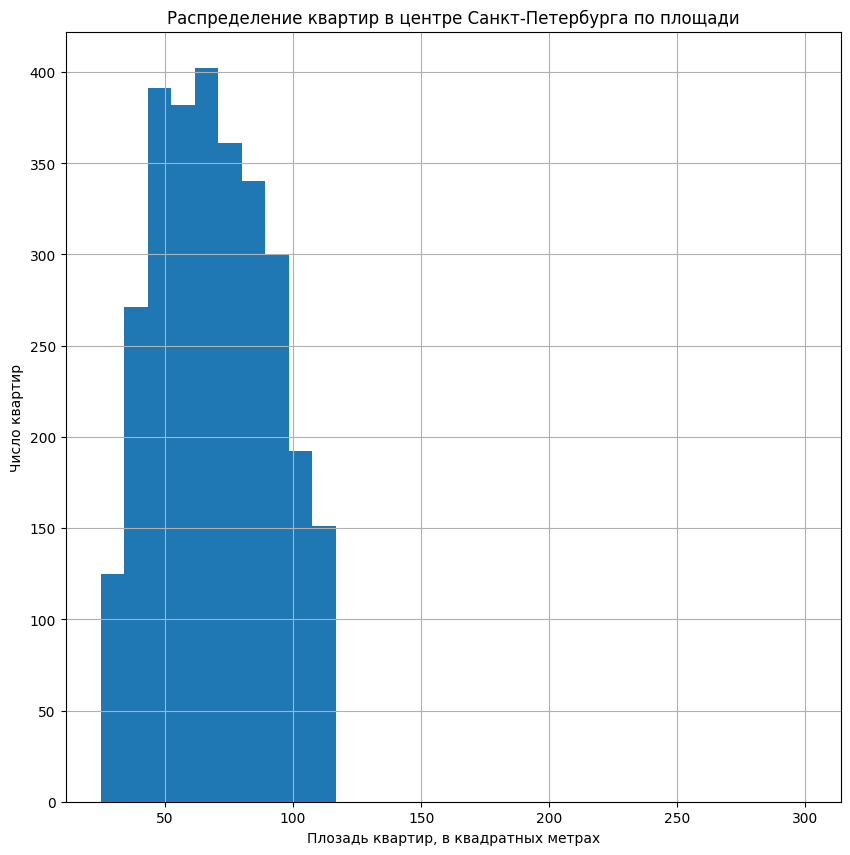

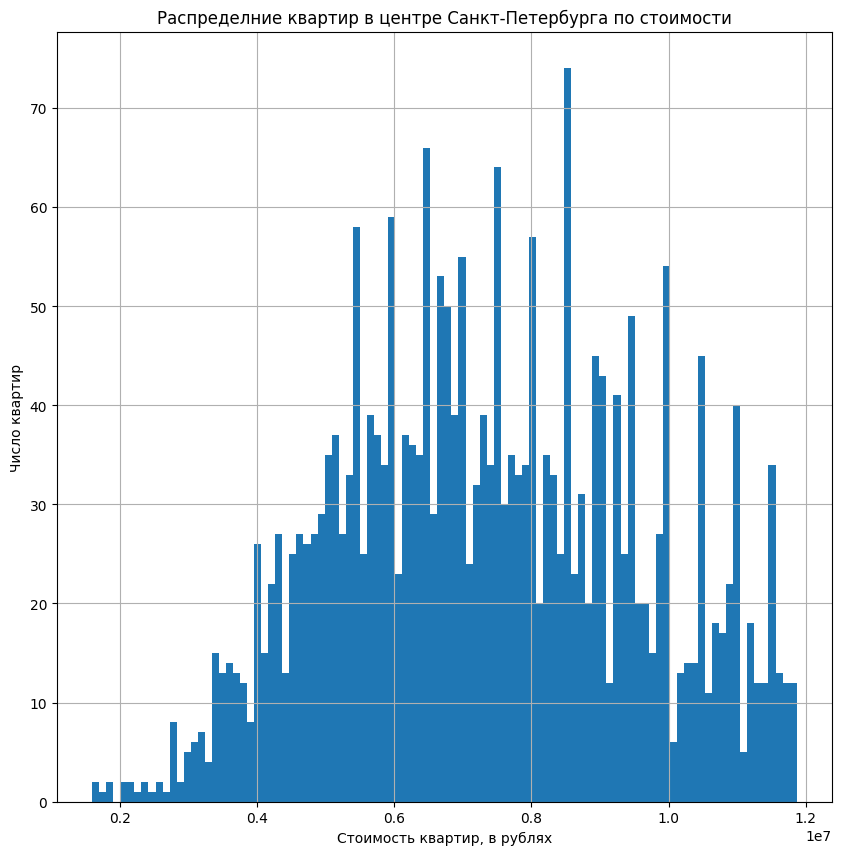

Высота потолков по городу (медиана): 3 

Высота потолков в центре (медиана): 3 

Высота потолков по городу (среднее): 3 

Высота потолков в центре (среднее): 3 



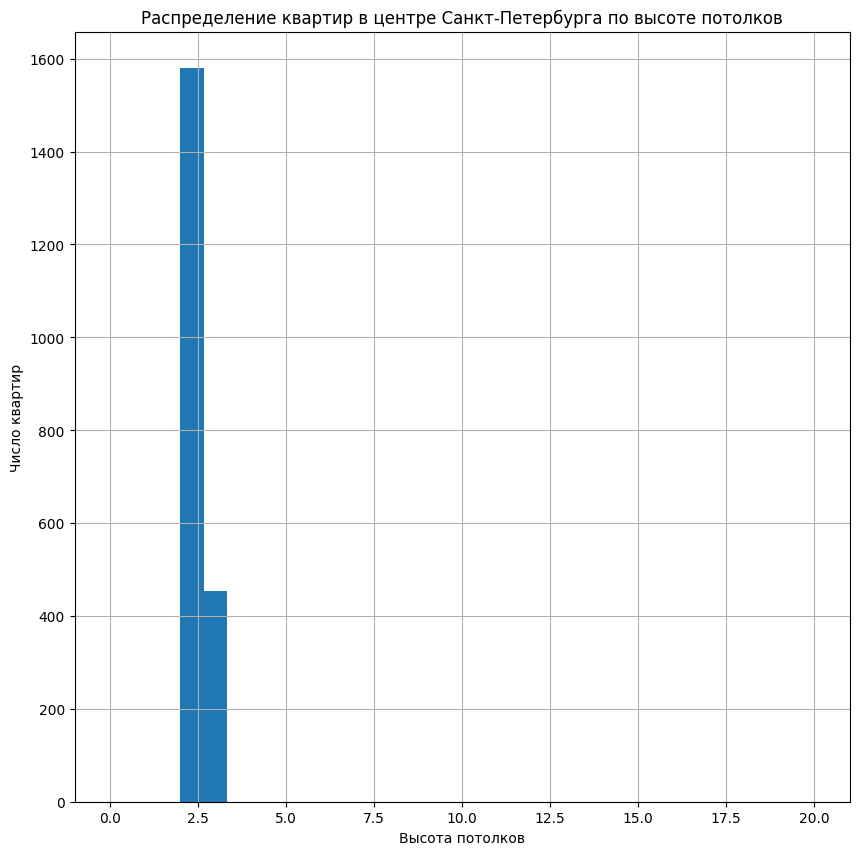

,count_centre,floor
rooms,,
1,4912,579
2,5082,1119
3,4107,1161
4,966,503
5,290,220


In [43]:
# Изучаем параметр "Площадь"
print('Площадь по городу (медиана):', round(df.query('locality_name == "Санкт-Петербург"')['total_area'].median()), '\n')
print('Площадь в центре (медиана):', round(piter_centre['total_area'].median()), '\n')
print('Площадь по городу (среднее):', round(df.query('locality_name == "Санкт-Петербург"')['total_area'].mean()), '\n')
print('Площадь в центре (среднее):', round(piter_centre['total_area'].mean()), '\n')
piter_centre['total_area'].hist(bins=30, range=(25,300), figsize=(10,10))
plt.title('Распределение квартир в центре Санкт-Петербурга по площади')
plt.ylabel('Число квартир')
plt.xlabel('Плозадь квартир, в квадратных метрах')
plt.show()

# Изучаем параметр "цена на момент снятия с публикации"
piter_centre['last_price'].hist(bins=100, figsize=(10,10))
plt.title('Распределние квартир в центре Санкт-Петербурга по стоимости')
plt.ylabel('Число квартир')
plt.xlabel('Стоимость квартир, в рублях')
plt.show()

# Изучаем параметр "высота потолков"
print('Высота потолков по городу (медиана):', round(df.query('locality_name == "Санкт-Петербург"')['ceiling_height'].median()), '\n')
print('Высота потолков в центре (медиана):', round(piter_centre['ceiling_height'].median()), '\n')
print('Высота потолков по городу (среднее):', round(df.query('locality_name == "Санкт-Петербург"')['ceiling_height'].mean()), '\n')
print('Высота потолков в центре (среднее):', round(piter_centre['ceiling_height'].mean()), '\n')
piter_centre['ceiling_height'].hist(bins=30, range=(0,20), figsize=(10,10))
plt.title('Распределение квартир в центре Санкт-Петербурга по высоте потолков')
plt.ylabel('Число квартир')
plt.xlabel('Высота потолков')
plt.show()

# Изучаем параметр "число комнат"
piter_rooms = df.query('(locality_name == "Санкт-Петербург") & (rooms > 0)').pivot_table(index='rooms', values='floor', aggfunc='count')
piter_rooms.columns = ['count']
piter_centre_rooms = piter_centre.pivot_table(index='rooms', values='floor', aggfunc='count')
piter_rooms.columns = ['count_centre']
all_rooms_data = pd.merge(piter_rooms, piter_centre_rooms, 'left', on='rooms')
display(all_rooms_data)

**Выводы:**

Площадь квартир, находящихся в центре Санкт-Петербурга, в среднем больше на 13-16 квадратных метров, чем в квартирах по городу.

Средняя высота потолков везде одинаковая и соответствует нормам СНИП

Больше всего в городе 1-2-комнатных квартир, что соответствует современной городской застройке - такие многоквартирные дома в Петербурге находятся на окраине города. В центре же больше всего 3-комнатных квартир. Если связать этот факт с большой площадью самих квартир в центре, то можно сделать вывод о том, что на продажу выставлены квартиры в доходных домах, построенных еще в дореволюционное время

В следующих действиях посмотрим взаимосвязь цен квартир в центре с остальными параметрами.

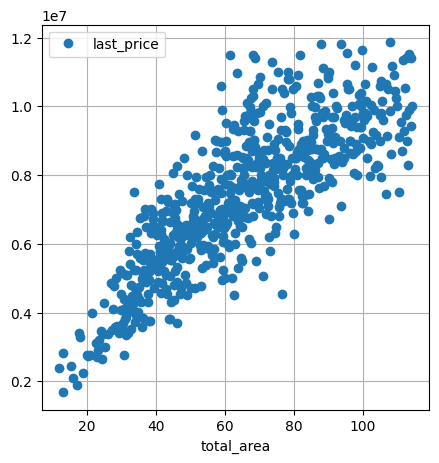

Корреляция цены и площади: 

            last_price  total_area
last_price    1.000000    0.572238
total_area    0.572238    1.000000 



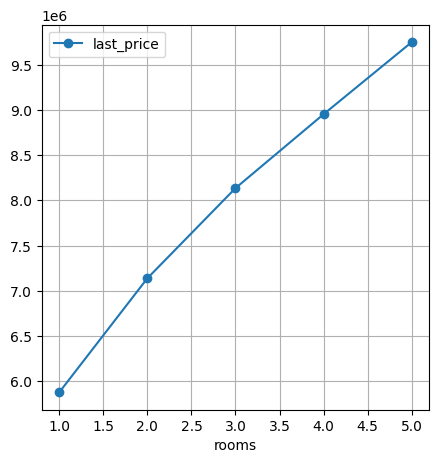

Корреляция цены и числа комнат: 

            last_price     rooms
last_price    1.000000 -0.137141
rooms        -0.137141  1.000000 



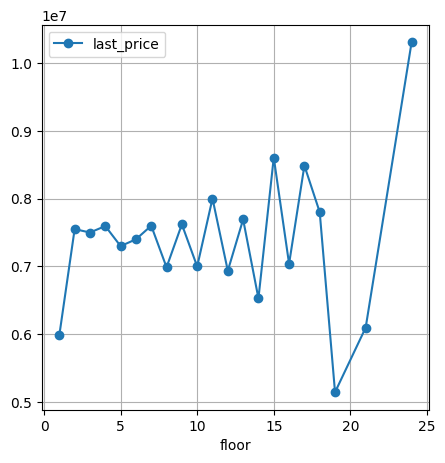

Корреляция цены и этажа: 

               floor  last_price
floor       1.000000   -0.854416
last_price -0.854416    1.000000 



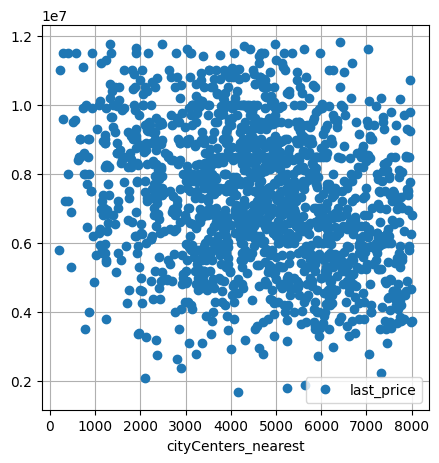

Корреляция цены и удалённости от центра: 

                     cityCenters_nearest  last_price
cityCenters_nearest             1.000000    0.124077
last_price                      0.124077    1.000000 



In [44]:
# Зависимость цены от площади
(
    piter_centre.pivot_table(index='total_area', values='last_price')
    .plot(grid=True, style='o', figsize=(5, 5))
)
plt.show()
print('Корреляция цены и площади:','\n')
print(piter_centre.pivot_table(index='floor', values=['total_area', 'last_price']).corr(),'\n')

# Зависимость цены от числа комнат
(
    piter_centre.query('rooms > 0').pivot_table(index='rooms', values='last_price')
    .plot(grid=True, style='o-', figsize=(5, 5))
)
plt.show()
print('Корреляция цены и числа комнат:','\n')
print(piter_centre.query('rooms > 0').pivot_table(index='floor', values=['rooms', 'last_price']).corr(),'\n')

# Зависимость цены от этажа
(
    piter_centre.pivot_table(index='floor', values='last_price', aggfunc='median')
    .plot(grid=True, style='o-', figsize=(5, 5))
)
plt.show()
print('Корреляция цены и этажа:','\n')
print(piter_centre.query('rooms > 0').pivot_table(index='rooms', values=['floor', 'last_price']).corr(),'\n')

# Зависимость цены от удалённости от центра
(
    piter_centre.pivot_table(index='cityCenters_nearest', values='last_price', aggfunc='median')
    .plot(grid=True, style='o', figsize=(5, 5))
)
plt.show()
print('Корреляция цены и удалённости от центра:','\n')
print(piter_centre.pivot_table(index='floor', values=['cityCenters_nearest', 'last_price']).corr(),'\n')

Проследим зависимость цены от времени года:

<Axes: xlabel='day_of_week'>

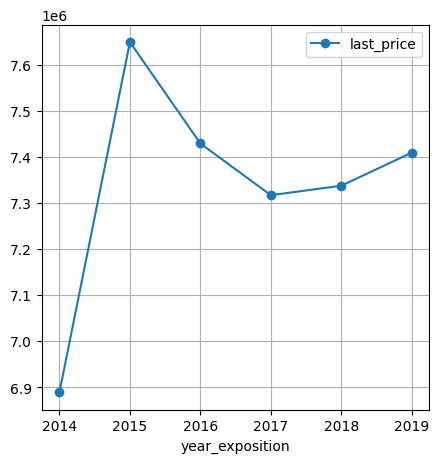

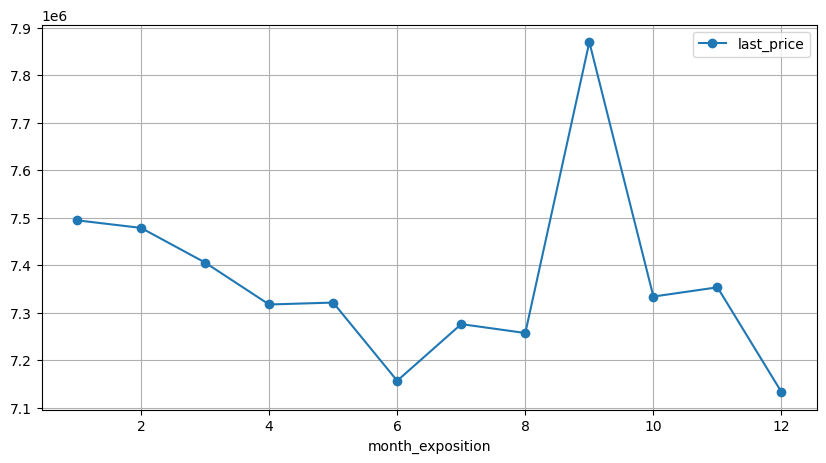

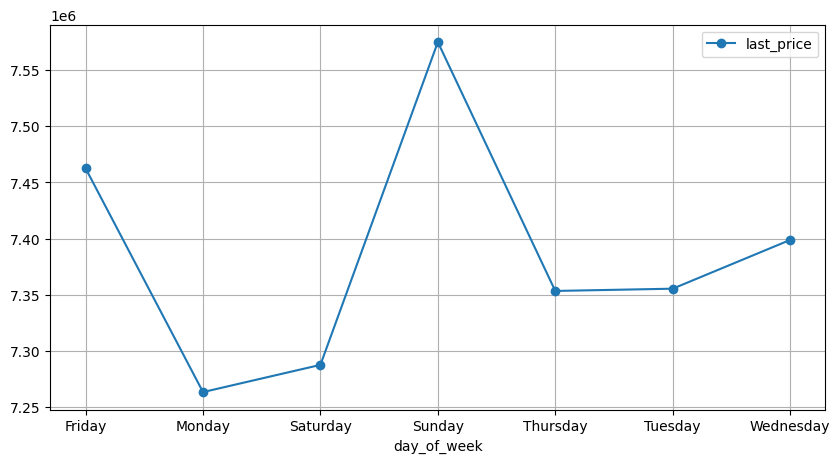

In [45]:
# Зависимость цены от года размещения
(
    piter_centre.pivot_table(index='year_exposition', values='last_price')
    .plot(grid=True, style='o-', figsize=(5, 5))
)

# Зависимость цены от месяца размещения
(
    piter_centre.pivot_table(index='month_exposition', values='last_price')
    .plot(grid=True, style='o-', figsize=(10, 5))
)

# Зависимость цены от дня недели размещения объявления
(
    piter_centre.pivot_table(index='day_of_week', values='last_price')
    .plot(grid=True, style='o-', figsize=(10, 5))
)

**Выводы:**

1. Зависимость цены квартиры от числа комнат в центре такая же, как и в целом по городу
2. Сложно проследить корреляцию между ценой квартиры в центре и этажом, на котором она расположена. Но тем не менее можно сказать, что чем выше находится квартира, тем она дороже. Можно только отметить, что после 8 этажа четные этажи имеют меньшую стоимость, чем нечетные;
3. В центре цена квариры зависит от количества комнат: чем больше комнат в квартире, тем цена выше;
4. В центральной зоне почти нет зависимости от удалённости от центра города. Стоимость даже немного повышается при удалении от центра - вероятно, это связано с расположением точки, которая является формальным центром города;
5. В центре значительно выше стоимость квартир, опубликованных в воскресенье и в сентябре. Стоимость резко падает в декабре (вероятно, перед Новым годом люди хотят завершить начатое дело по продаже квартиры);
6. Стоимость квартир в центре значительно выросла в 2015 году и максимально снизилась только в 2017 году. Это сложно объяснить, т.к. стоимость менее элитной недвижимости упала после обвала рубля в 2014 году

<a id="section-7"></a>

## Общий вывод

В ходе аналитической работы был проведен исследовательский анализ данных объявлений о продаже квартир в Санкт-Петербурге и Ленинградской области.
Были последовательно проведены следующие действия по преобразованию исходного датасета:
1. Изучена общая информация о датасете (*Применены методы .describe() и .info()*);
2. Произведена предобработка данных - структурирование, очистка, поиск дубликатов, заполнение пустых значений (*Применены методы .isna(), .fillna(), .dropna()*);
3. Произведены расчеты в данных: добавлены столбцы с годом, месяцем и днем недели объявления о продаже квартиры, найдены отношения жилой площади и площади кухни к общей площади квартиры;
4. Проведен исследовательский анализ данных с построением диаграмм (*Применены методы .hist(), .plot(), .pivot_table()*).

По итогам проведенного исследования получены следующие выводы:

**Срок продажи квартиры**

Чаще всего квартиру продают за 95 дней. Если меньше 45 дней, то это быстро, если дольше 230 дней - это долго.
Есть большое число квартир, проданных всего за несколько дней после публикации.
Также есть варианты, которые продавались несколько десятков месяцев.

**Факторы, влияющие на стоимость**

На стоимость больше влияет площадь квартиры, нежели число комнат. Т.е. могут быть дорогие квартиры с малым числом комнат, но где комнаты просторные.
Первый этаж значительно дешевле остальных вариантов. Также стоимость квартиры на последнем этаже ниже, чем на остальных, кроме первого.

**Стоимость квадратного метра в топ-10 населённых пунктов**

Дороже всего квадратный метр в Санкт-Петербурге - 114868.  Дешевле всего квадратный метр в Выборге - 58141

**Факторы, влияющие на стоимость в центре Санкт-Петербурга**

В центре города практически нет разницы, насколько квартира удалена от условного центра города.
Прослеживается зависимость, что чем выше этаж, тем квартира дороже.
Чем 
Экономическая ситуация в стране мало влияет на элитную недвижимость в центре